# Model comparison with the ZOIB linking: length scale (GP vs flat)

The ZOIB-linking counterpart of `study9-gp-vs-flat.ipynb`. Two models of the Study 9 ratings, differing
only in whether coherence generalization is distance-based: the length scale is fitted, or pinned flat. The
2d UMAP embedding is used.

- **fitted**: `length_scale` from its own posterior, so coherence generalizes locally in embedding space.
- **flat** (distance-blind null): `length_scale = LS_FLAT = 10`, far larger than the embedding's
  pairwise distances (max ≈ 0.78), so the kernel is constant across the cloud: training raises coherence
  uniformly, not by distance.

**Linking function:** the per-feature ZOIB (`linking.py`). Each feature has two components (kind-linked /
not kind-linked), each a zero/one-inflated Beta with its own P(0), P(100) and single-peaked Beta, profiled
at each model's own θ from the ratings-free coherence (`inference.total_log_lik_zoib`). Ratings are raw
(no half-bin nudge).

Every model uses its own posterior-median parameters and its own profiled linking, so neither borrows the
other's `(mu_0, sigma, beta)` or linking function.

Comparison metric: summed Laplace marginal likelihood `log Z` (higher = better), plus the VBMC ELBO. Both
models use the same ZOIB likelihood, so their numbers are directly comparable with each other, **but not
with the free-linking numbers in `study9-gp-vs-flat.ipynb`** (different linking likelihoods).

Predictive check: forward-pass `E[rating]` per feature under the ZOIB mixture vs the empirical mean,
pooled and per condition. As in the original notebook, the forward pass uses the coherence mode
**conditioned on the ratings** (`pred_posterior`); section 2b adds the ratings-free version
(`pred_prior`), which is the stricter test.

Source posteriors:
- `fitted` -> `results/study9-fit-zoib/posterior.npz` (4-D)
- `flat`   -> `results/study9-fit-zoib/posterior-null.npz` (3-D, ls = LS_FLAT)

Figures are saved to `results/study9-fit-zoib/` under names that don't collide with any existing file.

In [32]:
DATA_CSV = '../../data/study9_prereg.csv'

import os
os.environ.setdefault("JAX_ENABLE_X64", "1")
import sys
sys.path.insert(0, ".")

import json
import numpy as np
import matplotlib.pyplot as plt
import plot_style
plot_style.use_lexend()          # Lexend everywhere (DejaVu Sans fills in σ/β)
import jax.numpy as jnp

import inference as inf
import linking as lk

RESULTS = os.path.join('results', 'study9-fit-zoib')
MODEL_SPECS = {                              # model -> posterior file in RESULTS
    'fitted': 'posterior.npz',
    'flat':   'posterior-null.npz',
}
N_PARAMS = {'fitted': 4, 'flat': 3}  # free (mu_0, sigma, [ls], beta)

def _load_median(fname):
    z = np.load(os.path.join(RESULTS, fname), allow_pickle=True)
    return {'ls':    float(np.median(z['ls_samples'])),
            'mu_0':  float(np.median(z['mu0_samples'])),
            'sigma': float(np.median(z['sigma_samples'])),
            'beta':  float(np.median(z['beta_samples'])),
            'elbo':  float(json.loads(str(z['meta']))['elbo']),
            'file':  fname}

MODELS = {name: _load_median(f) for name, f in MODEL_SPECS.items()}
assert MODELS['flat']['ls'] == inf.LS_FLAT, "flat model should have ls pinned at LS_FLAT"

print(f"embedding space: 2d   (flat ls = {inf.LS_FLAT:g})")
print(f"{'model':<13}{'ls':>8}{'mu_0':>8}{'sigma':>8}{'beta':>8}{'n_params':>10}{'ELBO':>10}")
for name, m in MODELS.items():
    print(f"{name:<13}{m['ls']:>8.3g}{m['mu_0']:>+8.3f}{m['sigma']:>8.3f}{m['beta']:>8.3f}{N_PARAMS[name]:>10}{m['elbo']:>10.1f}")

geom = inf.load_geometry()
J = geom['J']
test_feature_names, test_trait = geom['test_feature_names'], geom['test_trait']
responses_cond, _ = inf.load_responses(DATA_CSV, clip_interior=False)    # RAW ratings for the ZOIB
emp_cond = {c: np.array(responses_cond[c]).mean(0) for c in inf.CONDITIONS}
N_cond   = {c: int(responses_cond[c].shape[0]) for c in inf.CONDITIONS}

MODEL_COLOR = {'fitted': '#2a78d6', 'flat': '#eb6834'}
TRAIT_COLOR = {'diet': '#2a78d6', 'personality': '#eb6834', 'physical': '#1baf7a'}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False})

embedding space: 2d   (flat ls = 10)
model              ls    mu_0   sigma    beta  n_params      ELBO
fitted          0.344  +1.293   0.522  25.931         4   -1724.9
flat               10  +1.480   0.429  22.801         3   -1731.8


## Compute: profiled ZOIB linking, log Z, and forward-pass predictions per model

For each model, at its own `(ls, mu_0, sigma, beta)`: profile the per-feature ZOIB linking, take the
per-condition Laplace `log Z`, and run the forward pass to a predicted `E[rating]` per feature per
condition, both from the ratings-conditioned coherence mode (as in the original notebook) and from the
ratings-free one. Everything downstream reads from `fitres`.

In [3]:
fitres = {}
for name, m in MODELS.items():
    ll, link_theta, cond_data = inf.total_log_lik_zoib(
        geom, responses_cond, m['ls'], m['mu_0'], m['sigma'],
        beta_speaker=m['beta'], return_link=True)
    p = lk.unpack(jnp.asarray(link_theta))
    pz1_prior = inf.prior_pz1_modes(geom, m['ls'], m['mu_0'], m['sigma'], beta_speaker=m['beta'])
    logZ_c, pred_cond, pz1_cond, pred_prior = {}, {}, {}, {}
    for c in inf.CONDITIONS:
        logZ_c[c], y_hat, ok = inf.laplace_log_Z(cond_data[c], m['ls'], m['mu_0'], m['sigma'],
                                                  beta_speaker=m['beta'])
        assert ok, (name, c)
        pz1_cond[c]   = 1.0 / (1.0 + np.exp(-y_hat[:J]))
        pred_cond[c]  = lk.expected_rating(p, pz1_cond[c])
        pred_prior[c] = lk.expected_rating(p, pz1_prior[c])
    fitres[name] = {'ll': ll, 'logZ_c': logZ_c, 'link': lk.params_to_numpy(p),
                    'pred_cond': pred_cond, 'pz1_cond': pz1_cond,
                    'pred_prior': pred_prior, 'pz1_prior': {c: np.asarray(v) for c, v in pz1_prior.items()}}
    print(f"  {name:<13}: total log Z = {ll:8.1f}")

  fitted       : total log Z =  -1719.9
  flat         : total log Z =  -1726.6


## 1. Log-probability table

Summed Laplace `log Z` per condition and total, one column per model. `n_params` counts the free GP
parameters (`mu_0`, `sigma`, speaker `beta`, and `ls` where fitted); the linking is profiled, not counted, and is
treated identically across models. Higher `log Z` = better; a `+1` parameter buys at most ~`0.5*log(N)`
before it's not worth it, so read the deltas against parameter count. The VBMC ELBO (which also integrates
over θ) is shown alongside.

In [4]:
names = list(MODELS)

hdr = f"{'condition':<15}" + "".join(f"{n:>14}" for n in names)
print(hdr); print("-" * len(hdr))
for c in inf.CONDITIONS:
    print(f"{c:<15}" + "".join(f"{fitres[n]['logZ_c'][c]:>14.1f}" for n in names))
print("-" * len(hdr))
print(f"{'TOTAL log Z':<15}" + "".join(f"{fitres[n]['ll']:>14.1f}" for n in names))
print(f"{'VBMC ELBO':<15}" + "".join(f"{MODELS[n]['elbo']:>14.1f}" for n in names))
print(f"{'n_params':<15}" + "".join(f"{N_PARAMS[n]:>14d}" for n in names))

base = 'flat'
print(f"\nRelative to '{base}' (n_params={N_PARAMS[base]}):")
for n in names:
    print(f"  {n:<13}: log Z delta={fitres[n]['ll']-fitres[base]['ll']:+7.1f}   "
          f"ELBO delta={MODELS[n]['elbo']-MODELS[base]['elbo']:+7.1f}   (+{N_PARAMS[n]-N_PARAMS[base]} params)")

print(f"\nAIC-style score (lower=better, 2k - 2*logZ):")
aic = {n: 2*N_PARAMS[n] - 2*fitres[n]['ll'] for n in names}
for n in sorted(names, key=lambda k: aic[k]):
    print(f"  {n:<13}: {aic[n]:8.1f}")

condition              fitted          flat
-------------------------------------------
physical               -656.5        -657.6
diet                   -427.8        -429.7
personality            -234.4        -240.2
heterogeneous          -401.2        -399.1
-------------------------------------------
TOTAL log Z           -1719.9       -1726.6
VBMC ELBO             -1724.9       -1731.8
n_params                    4             3

Relative to 'flat' (n_params=3):
  fitted       : log Z delta=   +6.7   ELBO delta=   +6.9   (+1 params)
  flat         : log Z delta=   +0.0   ELBO delta=   +0.0   (+0 params)

AIC-style score (lower=better, 2k - 2*logZ):
  fitted       :   3447.8
  flat         :   3459.2


## 2. Model mean vs empirical mean of prevalence, per feature

Correlation between each model's forward-pass mean rating (ZOIB mixture, ratings-conditioned coherence) and
the empirical mean rating, per feature. Reported **pooled** (4 conditions × 15 features = 60 points) and
**split per condition** (15 features each).

As in the original: within a condition a flat model's coherence is (near-)constant, so all of its
per-feature spread comes from the per-feature linking, which carries each feature's level. What separates
flat from fitted is the cross-condition structure (section 2b).

r(model E[rating], empirical mean)  per feature   [ratings-conditioned coherence]

                       fitted          flat
-------------------------------------------
POOLED                 +0.918        +0.899
-------------------------------------------
physical               +0.928        +0.913
diet                   +0.959        +0.931
personality            +0.968        +0.955
heterogeneous          +0.981        +0.979


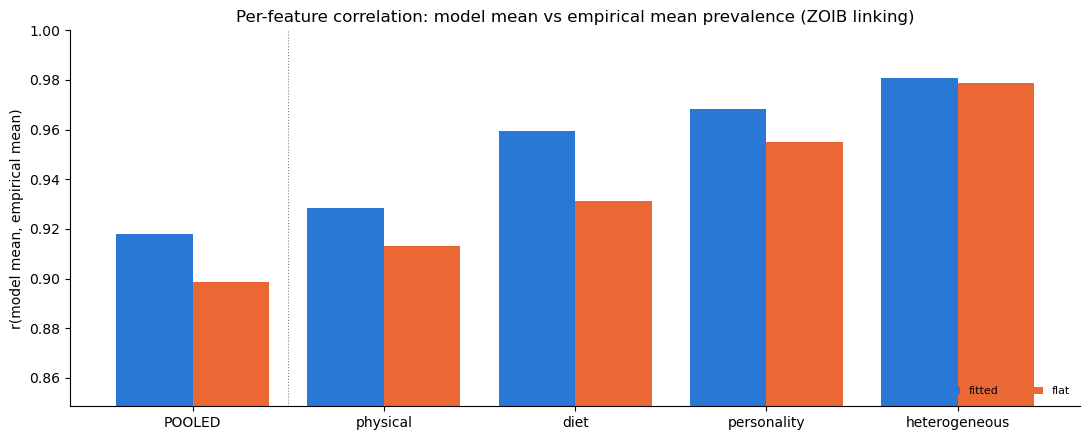

In [5]:
emp_all = np.concatenate([emp_cond[c] for c in inf.CONDITIONS])

def pooled(n, key='pred_cond'):
    return np.concatenate([fitres[n][key][c] for c in inf.CONDITIONS])

r_pool = {n: np.corrcoef(pooled(n), emp_all)[0, 1] for n in names}
r_cond = {n: {c: np.corrcoef(fitres[n]['pred_cond'][c], emp_cond[c])[0, 1] for c in inf.CONDITIONS}
          for n in names}

hdr = f"{'':<15}" + "".join(f"{n:>14}" for n in names)
print("r(model E[rating], empirical mean)  per feature   [ratings-conditioned coherence]\n")
print(hdr); print("-" * len(hdr))
print(f"{'POOLED':<15}" + "".join(f"{r_pool[n]:>+14.3f}" for n in names))
print("-" * len(hdr))
for c in inf.CONDITIONS:
    print(f"{c:<15}" + "".join(f"{r_cond[n][c]:>+14.3f}" for n in names))

fig, ax = plt.subplots(figsize=(11, 4.5))
groups = ['POOLED'] + list(inf.CONDITIONS)
xg = np.arange(len(groups)); w = 0.8 / len(names)
allv = []
for i, n in enumerate(names):
    vals = [r_pool[n]] + [r_cond[n][c] for c in inf.CONDITIONS]
    allv += vals
    ax.bar(xg + (i - (len(names)-1)/2)*w, vals, w, label=n, color=MODEL_COLOR[n])
ax.set_xticks(xg); ax.set_xticklabels(groups)
ax.set_ylabel('r(model mean, empirical mean)'); ax.set_ylim(max(0.0, min(allv) - 0.05), 1.0)
ax.axvline(0.5, color='gray', lw=0.8, ls=':')
ax.set_title('Per-feature correlation: model mean vs empirical mean prevalence (ZOIB linking)')
ax.legend(ncol=2, fontsize=8, loc='lower right')
plt.tight_layout(); plt.show()

### 2b. Ratings-free predictions and the R² split

The stricter version: predictions from the **ratings-free** coherence (training statements only, as in
`predictions.csv`'s `pred_prior`), with R² split into between-feature (each feature's level) and
within-feature (each feature's condition differences, the part only the coherence field can explain), and
the memorization baseline (each cell predicted by its feature's mean).

In [6]:
r2 = lambda a, e: 1 - np.sum((e - a) ** 2) / np.sum((e - e.mean()) ** 2)
E = np.stack([emp_cond[c] for c in inf.CONDITIONS])
rows = []
for n in names:
    for key, lab in [('pred_prior', 'ratings-free'), ('pred_cond', 'ratings-conditioned')]:
        P = np.stack([fitres[n][key][c] for c in inf.CONDITIONS])
        Pb, Eb = P.mean(0), E.mean(0)
        rows.append({'model': n, 'coherence': lab, 'R2 overall': r2(P.ravel(), E.ravel()),
                     'R2 between': r2(Pb, Eb), 'R2 within': r2((P - Pb).ravel(), (E - Eb).ravel())})
M = np.tile(E.mean(0), (len(inf.CONDITIONS), 1))
rows.append({'model': 'memorize: feature mean', 'coherence': '-', 'R2 overall': r2(M.ravel(), E.ravel()),
             'R2 between': 1.0, 'R2 within': 0.0})
import pandas as pd
pd.DataFrame(rows).set_index(['model', 'coherence']).round(3)

R2 overall  R2 between  R2 within
model                  coherence                                             
fitted                 ratings-free              0.776       0.997      0.042
                       ratings-conditioned       0.839       0.997      0.314
flat                   ratings-free              0.765       0.996      0.000
                       ratings-conditioned       0.805       0.996      0.172
memorize: feature mean -                         0.768       1.000      0.000

## 3. Coherence fields (2-d embedding)

One 2×2 figure per model (2 models × 4 conditions). **All panels share one color scale**, spanning the
global min/max across every field, so color is comparable across conditions and models. Under the flat
model the field is (near-)constant within a condition, so each panel is a uniform shade. Dark squares are
trained features; test features are circles filled by their empirical mean rating on a **separate** orange
scale (right colorbar), since ratings and coherence live on different ranges. Each figure is saved to
`results/study9-fit-zoib/gp-coherence-field-comparison-<model>.png`.

This cell computes the fields (a few seconds); the next one plots them.

In [23]:
all_x = np.vstack([np.array(geom['x_test'])] + [np.array(geom['x_train_cond'][c]) for c in inf.CONDITIONS])
pad = 0.08
(x_lo, y_lo), (x_hi, y_hi) = all_x.min(0) - pad, all_x.max(0) + pad
gx, gy = np.meshgrid(np.linspace(x_lo, x_hi, 80), np.linspace(y_lo, y_hi, 80))
X_grid = np.column_stack([gx.ravel(), gy.ravel()])
x_test_np = np.array(geom['x_test'])

fields, pz1_tests = {}, {}
for name, m in MODELS.items():
    for c in inf.CONDITIONS:
        fields[name, c]    = inf.gp_coherence_field(geom, c, m['ls'], m['mu_0'], m['sigma'],
                                                    X_grid, beta_speaker=m['beta']).reshape(gx.shape)
        pz1_tests[name, c] = inf.gp_coherence_field(geom, c, m['ls'], m['mu_0'], m['sigma'],
                                                    x_test_np, beta_speaker=m['beta'])
f_all = np.stack(list(fields.values()))
LEVELS = np.linspace(f_all.min(), f_all.max(), 21)
emin, emax = min(e.min() for e in emp_cond.values()), max(e.max() for e in emp_cond.values())
print(f"shared color scale across both models: [{f_all.min():.3f}, {f_all.max():.3f}]")

shared color scale across both models: [0.787, 0.845]


saved results/study9-fit-zoib/coherence-field-fig-fitted.png


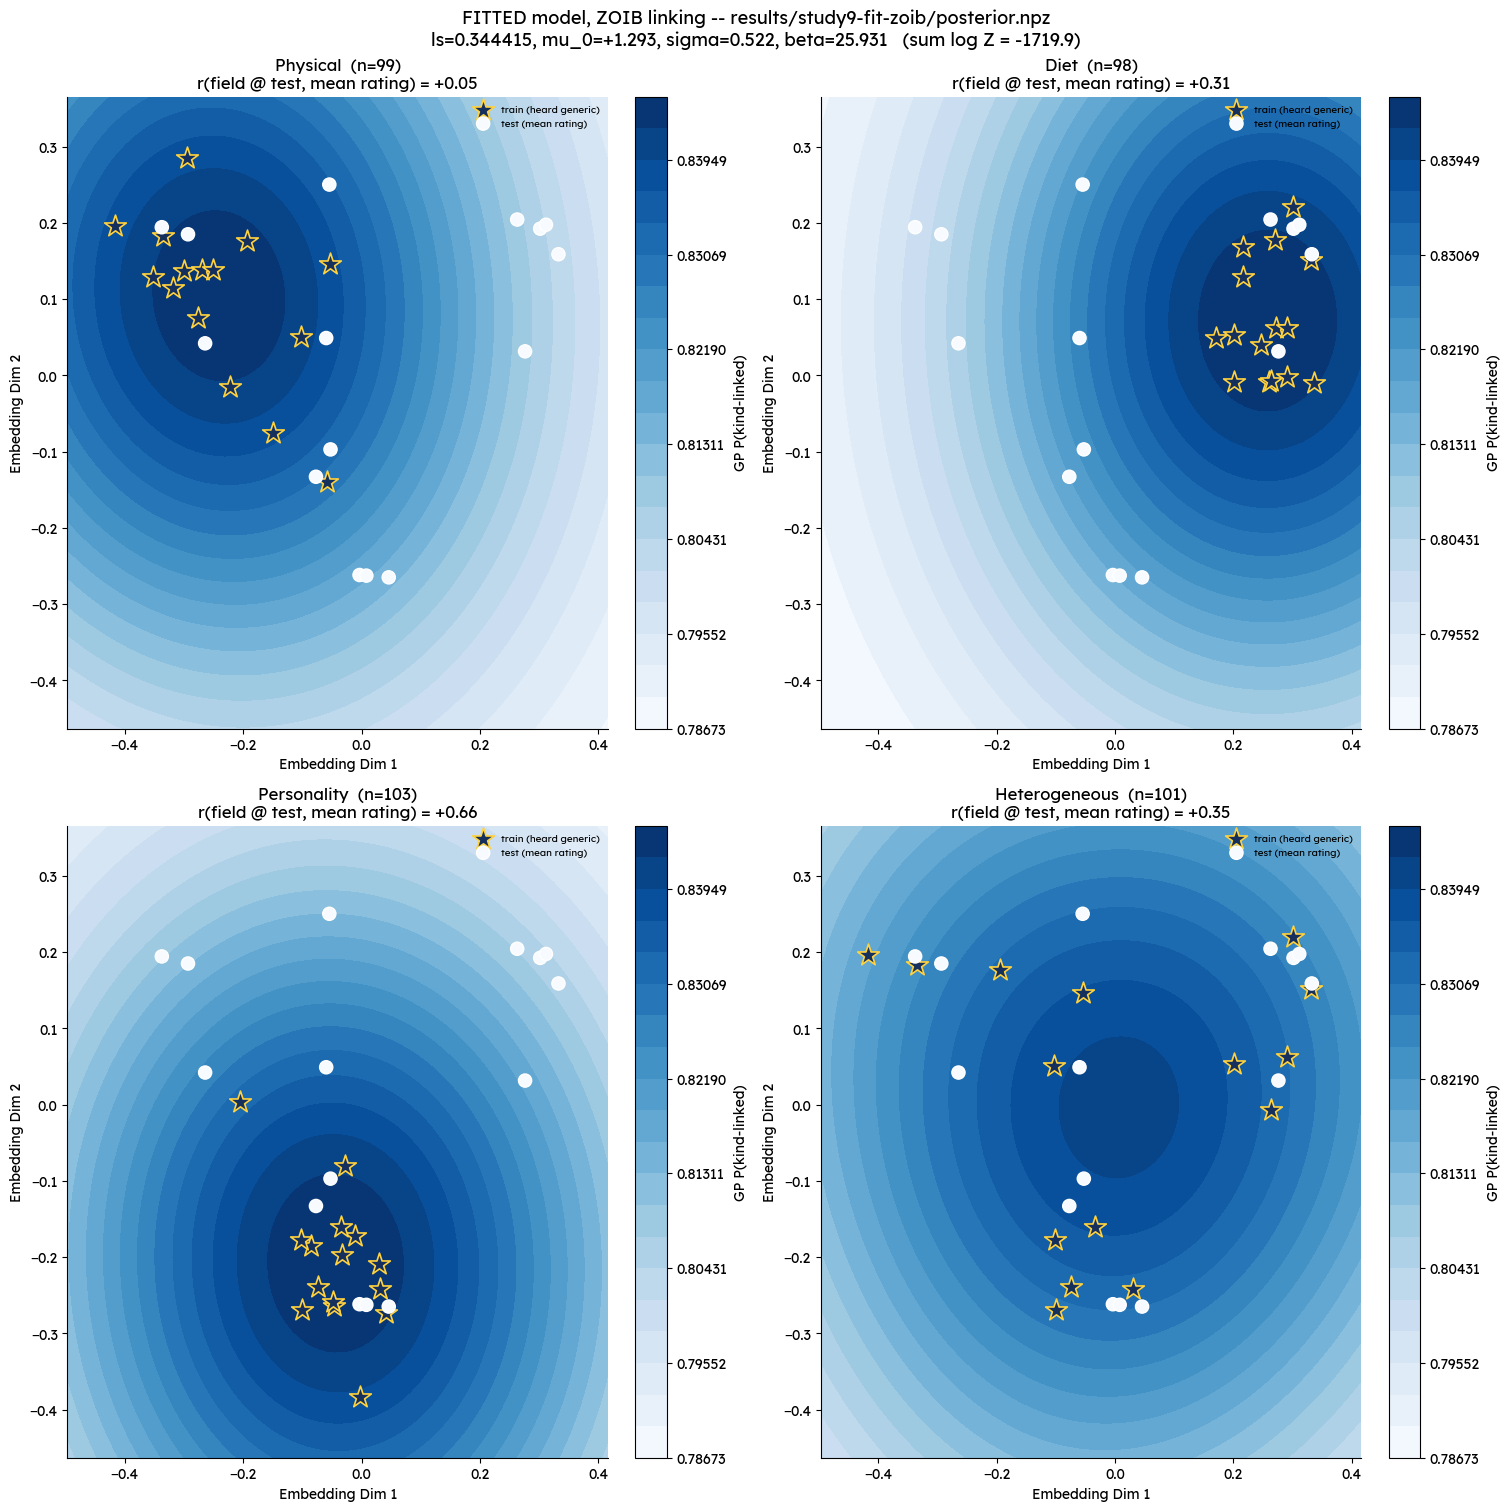

saved results/study9-fit-zoib/coherence-field-fig-flat.png


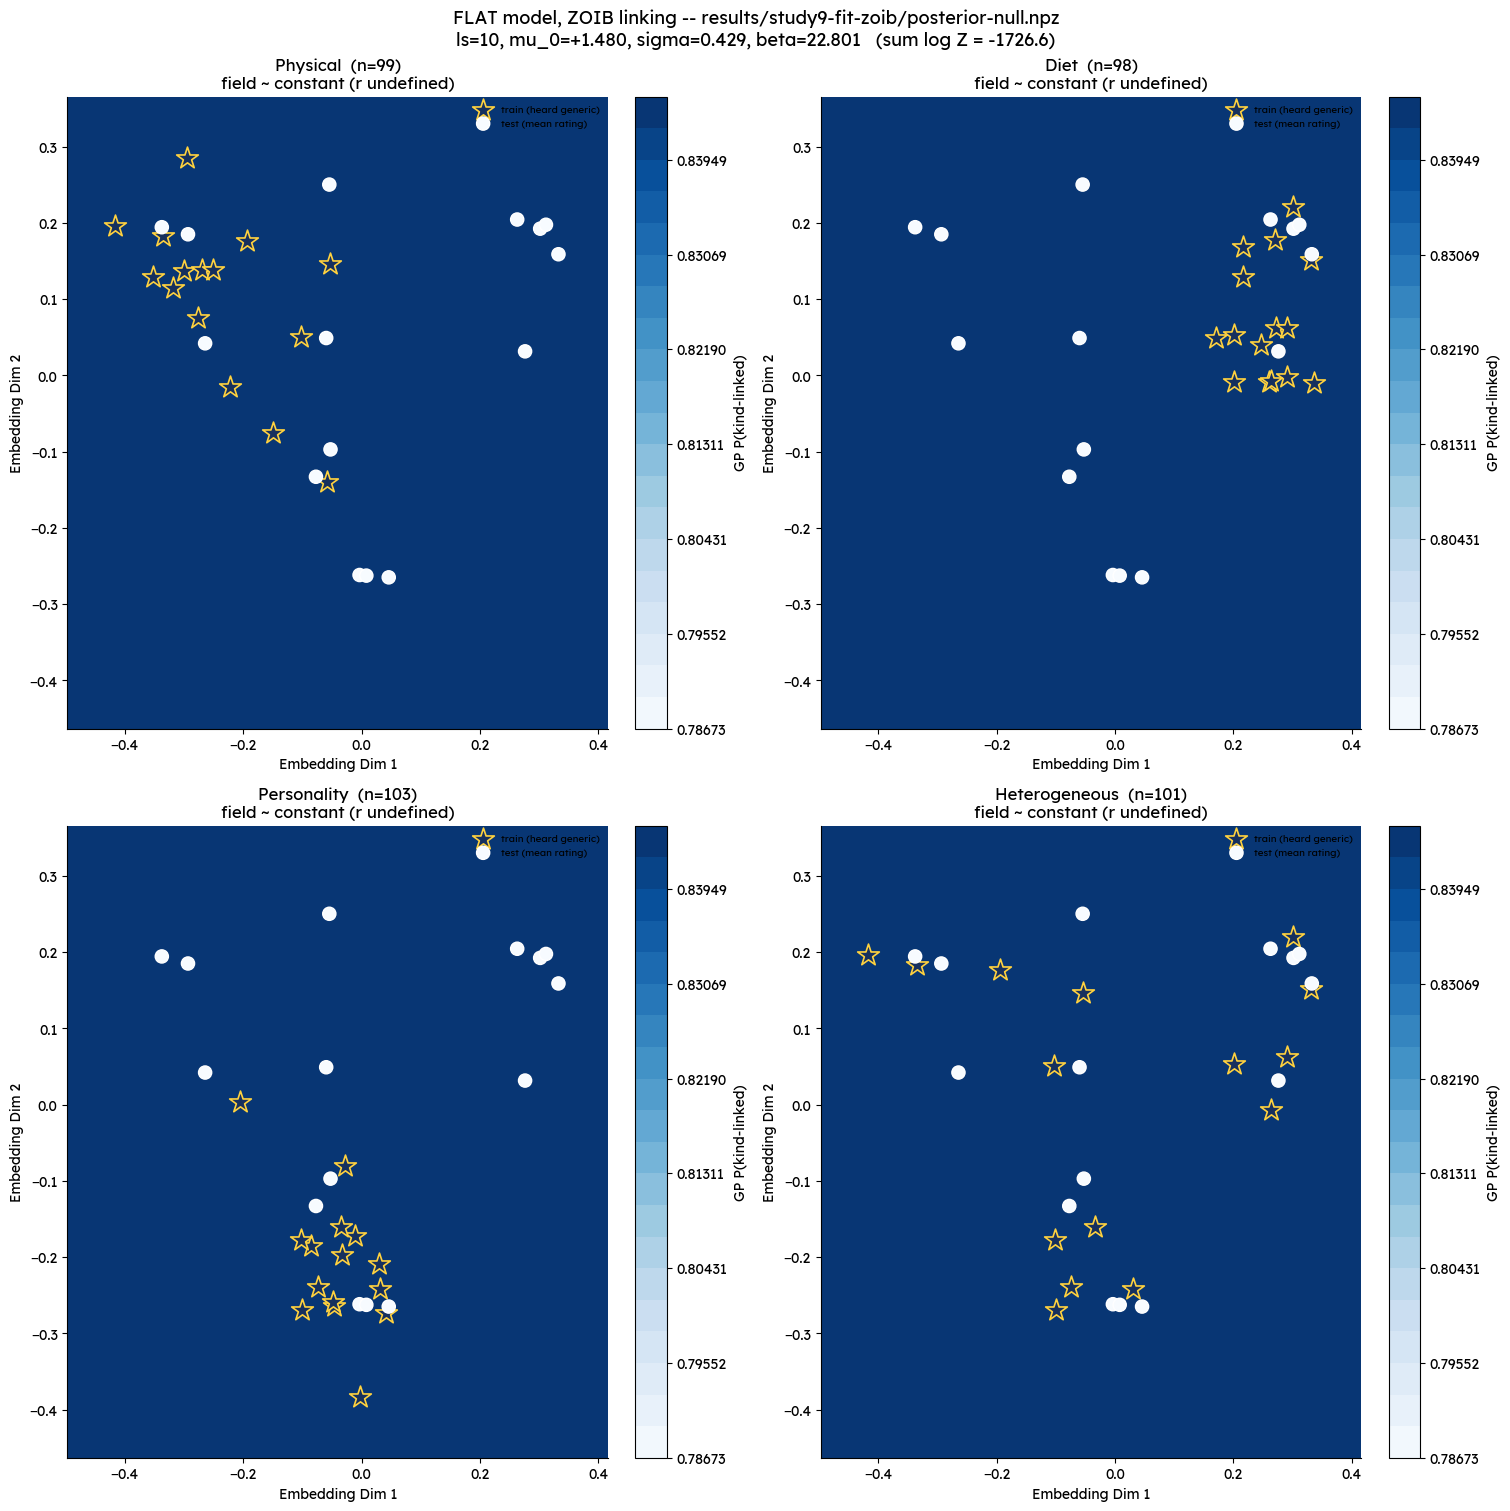

In [33]:
# color scheme as in the old model-comparison-gp-vs-flat.ipynb figure: the contours use LEVELS (the field's
# own min-max across BOTH models, 21 levels, from the compute cell above) with a colorbar per panel, and the
# test features are colored by their empirical mean rating on that SAME scale. Mean ratings outside the
# field's range clip to its lightest / darkest shade. Set RATINGS_OWN_SCALE = True to instead color the
# circles on their own range (then the circle colors are relative, not in coherence units).
RATINGS_OWN_SCALE = False

def plot_fields(name, m):
    fig, axes = plt.subplots(2, 2, figsize=(15, 15), layout='constrained')
    for ax, c in zip(axes.ravel(), inf.CONDITIONS):
        field, pz1_test = fields[name, c], pz1_tests[name, c]
        cs = ax.contourf(gx, gy, field, levels=LEVELS, cmap='Blues')
        cb = fig.colorbar(cs, ax=ax); cb.set_label('GP P(kind-linked)')
        x_tr = np.array(geom['x_train_cond'][c])
        ax.scatter(x_tr[:, 0], x_tr[:, 1], s=270, marker='*', color='#16305e', edgecolor='#ffd23f', lw=1.2,
                   zorder=3, label='train (heard generic)')
        sc = ax.scatter(x_test_np[:, 0], x_test_np[:, 1], s=90, c=emp_cond[c], cmap='Blues', **({'vmin': emin, 'vmax': emax} if RATINGS_OWN_SCALE else {'norm': cs.norm}),
                        edgecolor='white', linewidth=1, zorder=4, label='test (mean rating)')
        if np.ptp(pz1_test) > 1e-3:
            r_txt = f"r(field @ test, mean rating) = {np.corrcoef(pz1_test, emp_cond[c])[0, 1]:+.2f}"
        else:
            r_txt = 'field ~ constant (r undefined)'
        ax.set_title(f"{c.capitalize()}  (n={N_cond[c]})\n{r_txt}")
        ax.set_xlabel('Embedding Dim 1'); ax.set_ylabel('Embedding Dim 2')
        ax.legend(fontsize=7, loc='upper right')
    fig.suptitle(f"{name.upper()} model, ZOIB linking -- results/study9-fit-zoib/{m['file']}\n"
                 f"ls={m['ls']:g}, mu_0={m['mu_0']:+.3f}, sigma={m['sigma']:.3f}, beta={m['beta']:.3f}   "
                 f"(sum log Z = {fitres[name]['ll']:.1f})", fontsize=13)
    out_png = os.path.join(RESULTS, f"coherence-field-fig-{name}.png")
    fig.savefig(out_png, dpi=150, bbox_inches='tight')
    print('saved', out_png)
    plt.show()

for name, m in MODELS.items():
    plot_fields(name, m)

### 3a. Normalized version: where high goes with high, low with low

Same fields and test features, but **both rescaled to 0–1 within each condition panel**: the field by its
lowest / highest value over that panel (0 = lowest coherence in the panel, 1 = highest), and the 15 mean
ratings by that condition's lowest / highest mean rating. Both then share one 0–1 color scale, so a dark
circle on a dark patch = relatively high rating where the field is relatively high, and light on light =
relatively low on both. This shows *agreement in ordering*, not agreement in value; the r in each title is
the same correlation as in the unnormalized figure. A flat (constant) field can't be rescaled, so it's
drawn at a uniform 0.5. Saved to `results/study9-fit-zoib/coherence-field-fig-<model>-normalized.png`.

saved results/study9-fit-zoib/coherence-field-fig-fitted-normalized.png


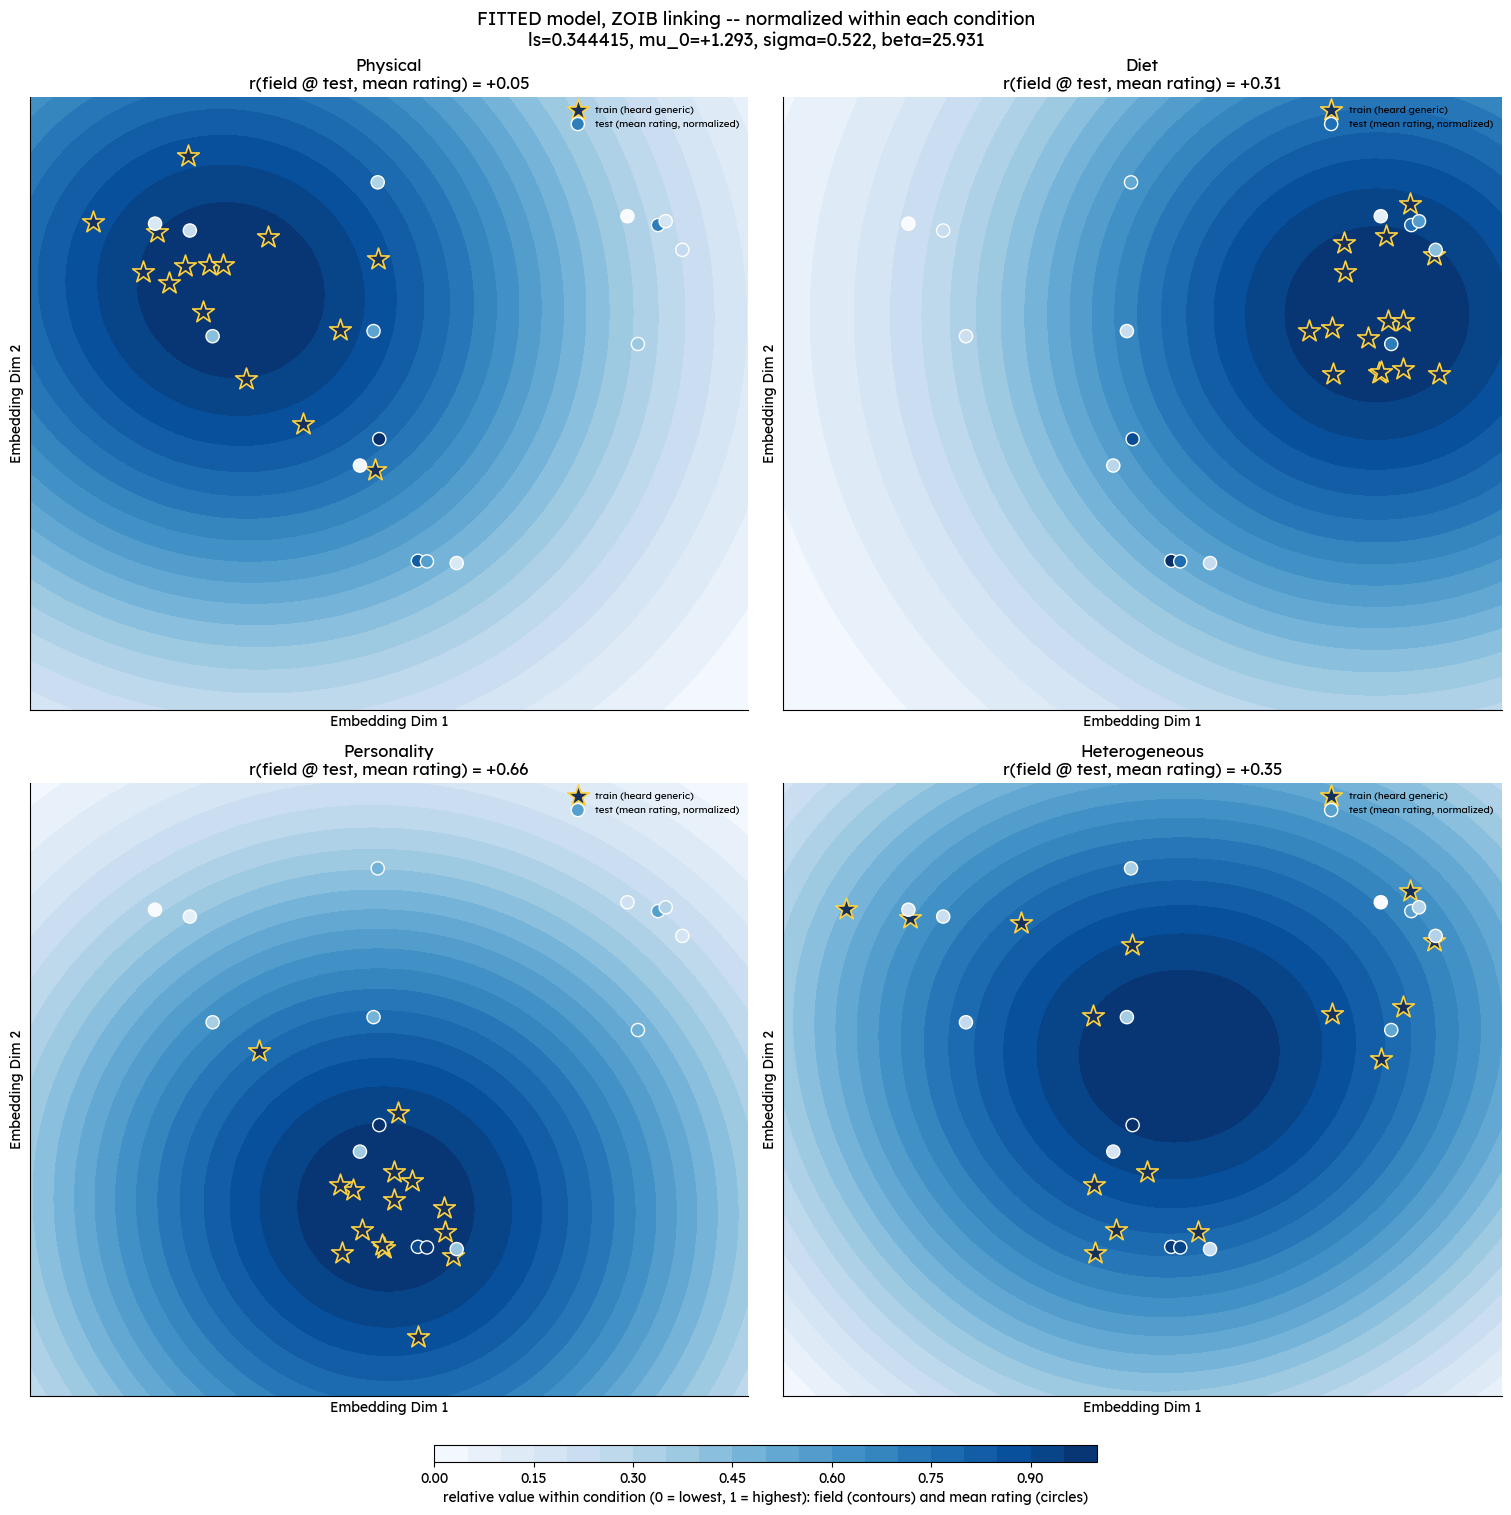

saved results/study9-fit-zoib/coherence-field-fig-flat-normalized.png


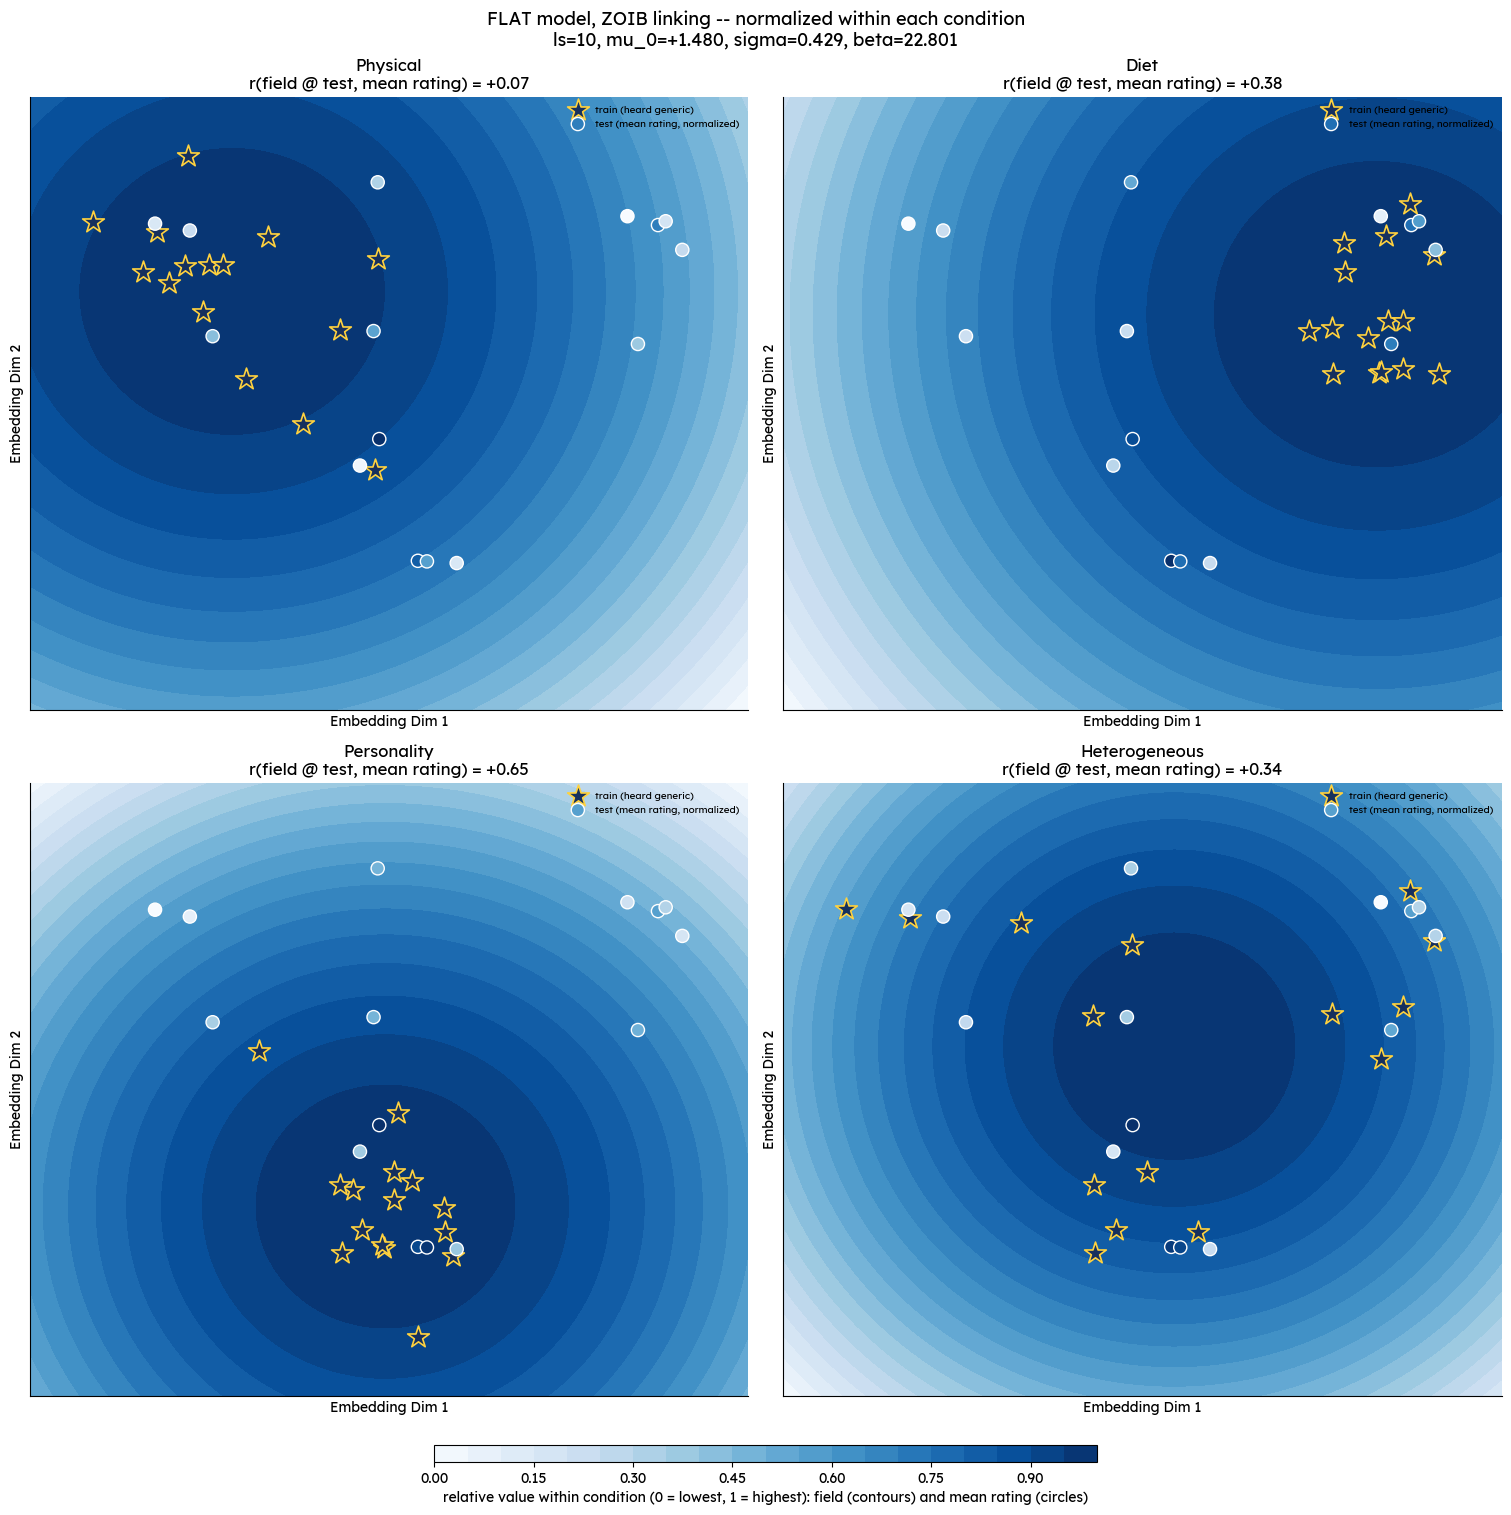

In [37]:
def minmax(v, lo, hi):
    return np.full_like(np.asarray(v, float), 0.5) if hi - lo < 1e-9 else (np.asarray(v, float) - lo) / (hi - lo)

NORM_LEVELS = np.linspace(0, 1, 21)

def plot_fields_normalized(name, m):
    fig, axes = plt.subplots(2, 2, figsize=(15, 15), layout='constrained')
    for ax, c in zip(axes.ravel(), inf.CONDITIONS):
        field, pz1_test = fields[name, c], pz1_tests[name, c]
        flat = np.ptp(field) < 1e-6
        field_n = minmax(field, field.min(), field.max())
        rating_n = minmax(emp_cond[c], emp_cond[c].min(), emp_cond[c].max())
        cs = ax.contourf(gx, gy, field_n, levels=NORM_LEVELS, cmap='Blues', vmin=0, vmax=1)
        x_tr = np.array(geom['x_train_cond'][c])
        ax.scatter(x_tr[:, 0], x_tr[:, 1], s=270, marker='*', color='#16305e', edgecolor='#ffd23f', lw=1.2,
                   zorder=3, label='train (heard generic)')
        ax.scatter(x_test_np[:, 0], x_test_np[:, 1], s=90, c=rating_n, cmap='Blues', vmin=0, vmax=1,
                   edgecolor='white', linewidth=1, zorder=4, label='test (mean rating, normalized)')
        if flat:
            r_txt = 'field constant (drawn at 0.5; r undefined)'
        else:
            r_txt = f"r(field @ test, mean rating) = {np.corrcoef(pz1_test, emp_cond[c])[0, 1]:+.2f}"
        ax.set_title(f"{c.capitalize()}\n{r_txt}")
        ax.set_xlabel('Embedding Dim 1'); ax.set_ylabel('Embedding Dim 2')
        ax.set_xticks([]); ax.set_yticks([])
        ax.legend(fontsize=7, loc='upper right')
    fig.colorbar(cs, ax=axes, location='bottom', shrink=0.45, aspect=40, pad=0.02,
                 label='relative value within condition (0 = lowest, 1 = highest): field (contours) and mean rating (circles)')
    fig.suptitle(f"{name.upper()} model, ZOIB linking -- normalized within each condition\n"
                 f"ls={m['ls']:g}, mu_0={m['mu_0']:+.3f}, sigma={m['sigma']:.3f}, beta={m['beta']:.3f}", fontsize=13)
    out_png = os.path.join(RESULTS, f"coherence-field-fig-{name}-normalized.png")
    fig.savefig(out_png, dpi=150, bbox_inches='tight')
    print('saved', out_png)
    plt.show()

for name, m in MODELS.items():
    plot_fields_normalized(name, m)

### 3b. Mean prevalence ratings on their own scale

The test features' empirical mean ratings per condition, without the field, on one color scale shared
across the four conditions and spanning the full range of mean ratings (so conditions can be compared).
Each circle sits at the feature's embedding position; the number is its mean rating. Stars = that
condition's training features, for reference. Drawn twice, without and with feature names; saved to `results/study9-fit-zoib/test-prevalence-by-condition.png` and `...-named.png`.

saved results/study9-fit-zoib/test-prevalence-by-condition.png


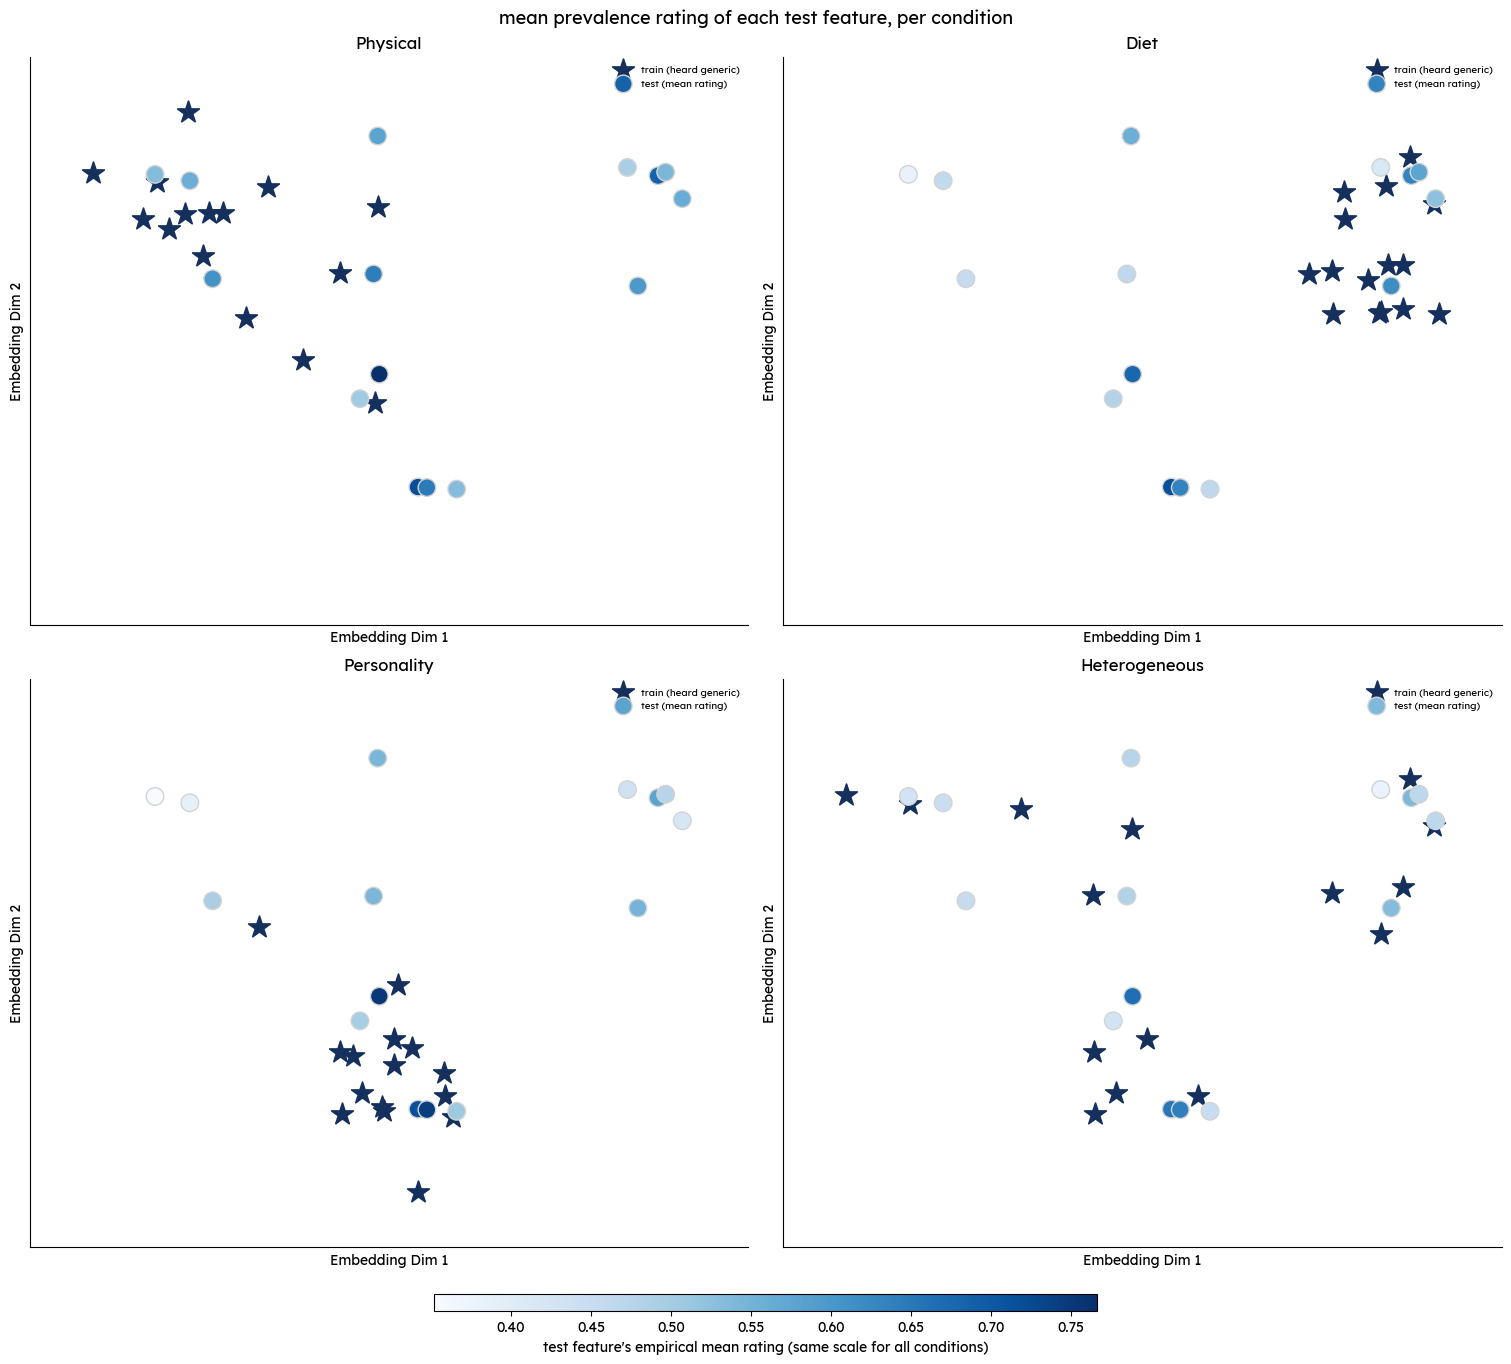

saved results/study9-fit-zoib/test-prevalence-by-condition-named.png


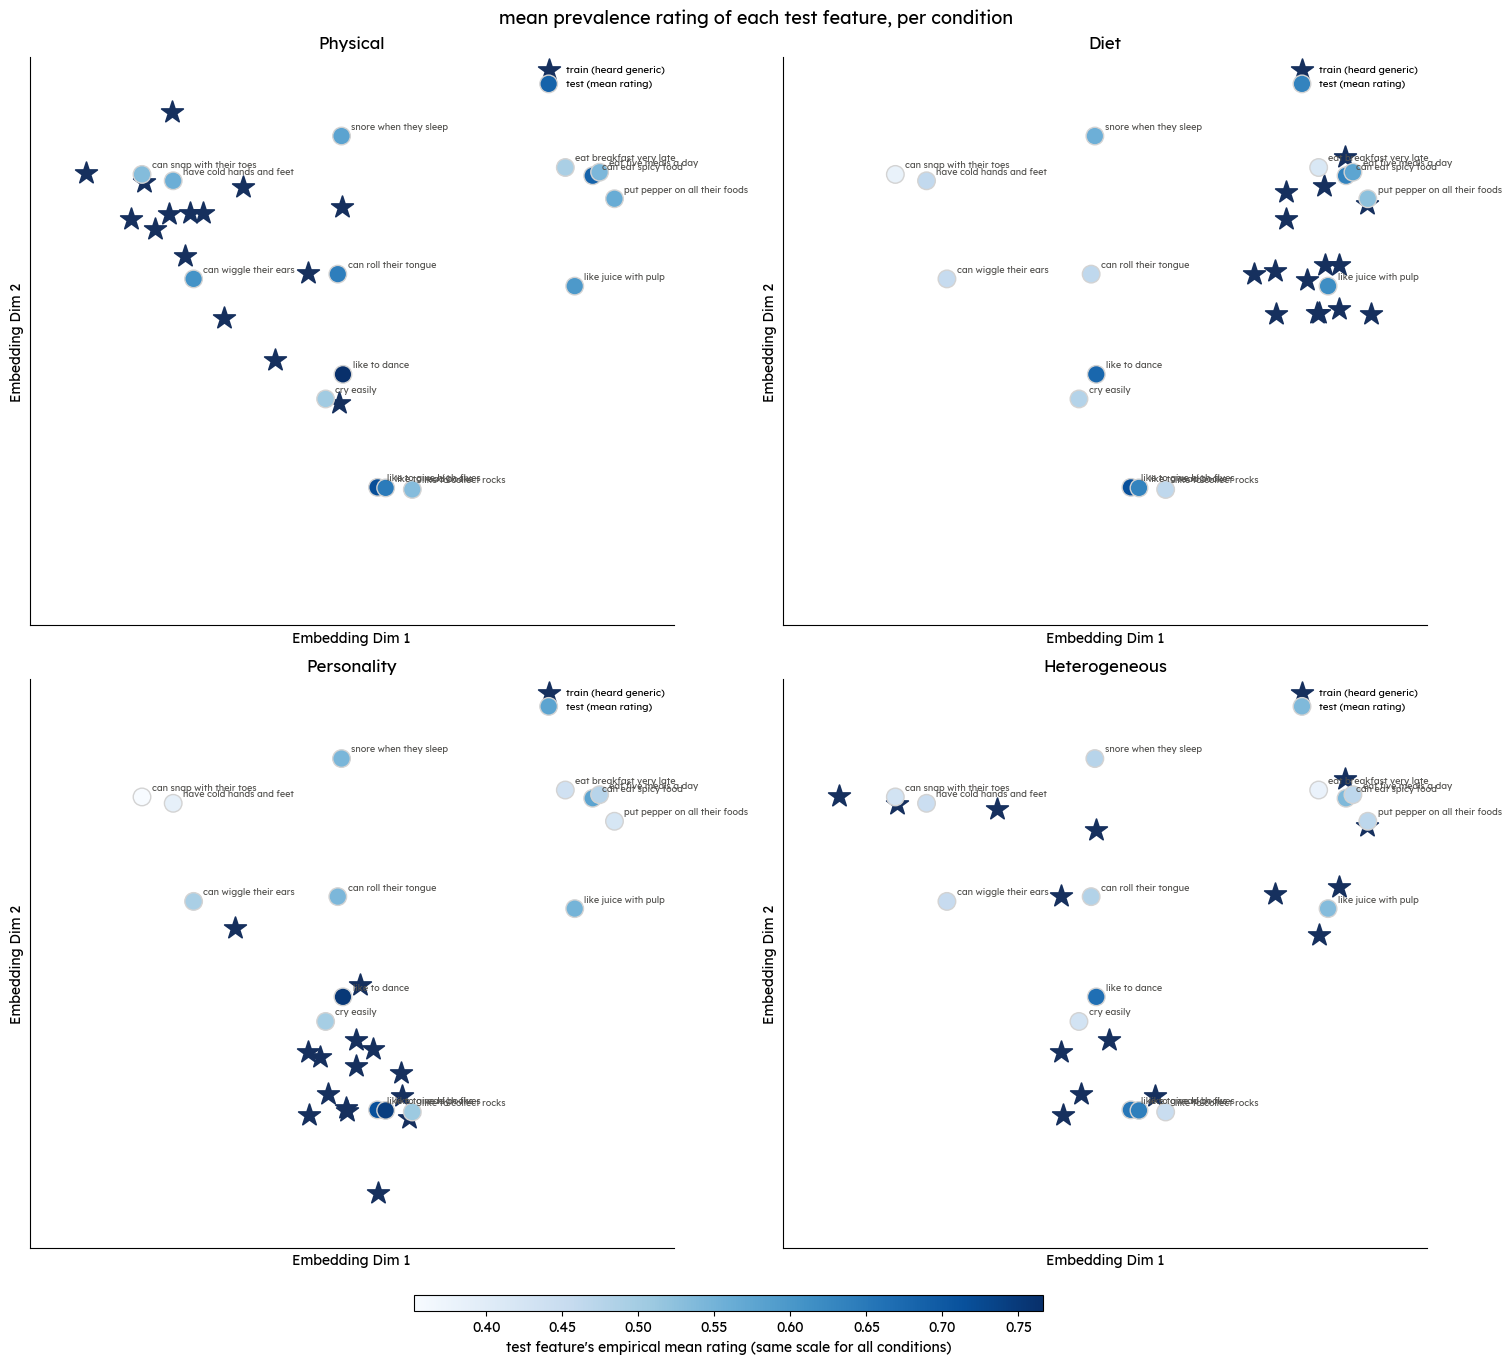

In [36]:
def plot_prevalence_by_condition(show_names=False):
    fig, axes = plt.subplots(2, 2, figsize=(15, 13.5), layout='constrained')
    for ax, c in zip(axes.ravel(), inf.CONDITIONS):
        x_tr = np.array(geom['x_train_cond'][c])
        ax.scatter(x_tr[:, 0], x_tr[:, 1], s=270, marker='*', color='#16305e', lw=1.2,
                   zorder=3, label='train (heard generic)')
        sc = ax.scatter(x_test_np[:, 0], x_test_np[:, 1], s=160, c=emp_cond[c], cmap='Blues', vmin=emin, vmax=emax,
                        edgecolor='lightgrey', linewidth=1, zorder=4, label='test (mean rating)')
        if show_names:
            for (xx, yy), nm in zip(x_test_np, test_feature_names):
                ax.annotate(nm, (xx, yy), xytext=(7, 5), textcoords='offset points', fontsize=6.5,
                            color='#52514e', zorder=5)
        ax.set_xlim(x_lo, x_hi); ax.set_ylim(y_lo, y_hi)
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(c.capitalize())
        ax.set_xlabel('Embedding Dim 1'); ax.set_ylabel('Embedding Dim 2')
        ax.grid(color='#e6e5e1', lw=0.6); ax.set_axisbelow(True)
        ax.legend(fontsize=7, loc='upper right')
    fig.colorbar(sc, ax=axes, location='bottom', shrink=0.45, aspect=40, pad=0.02,
                 label='test feature\'s empirical mean rating (same scale for all conditions)')
    fig.suptitle('mean prevalence rating of each test feature, per condition', fontsize=13)
    out_png = os.path.join(RESULTS, 'test-prevalence-by-condition' + ('-named' if show_names else '') + '.png')
    fig.savefig(out_png, dpi=150, bbox_inches='tight')
    print('saved', out_png)
    plt.show()

plot_prevalence_by_condition(show_names=False)
plot_prevalence_by_condition(show_names=True)

## 4. Predicted vs empirical prevalence per feature

One row of four condition-panels per model, each point a test feature colored by its trait
(diet / personality / physical), with the matched-condition trait outlined in black. `x` is the empirical
mean rating, `y` is the model's `E[rating]` (ratings-conditioned coherence, as in the original); the dashed
line is the identity. Panel subtitles give per-condition r; the row label gives the pooled r. Saved to
`results/study9-fit-zoib/predicted-vs-empirical-scatter-comparison.png`.

saved results/study9-fit-zoib/predicted-vs-empirical-scatter-comparison.png


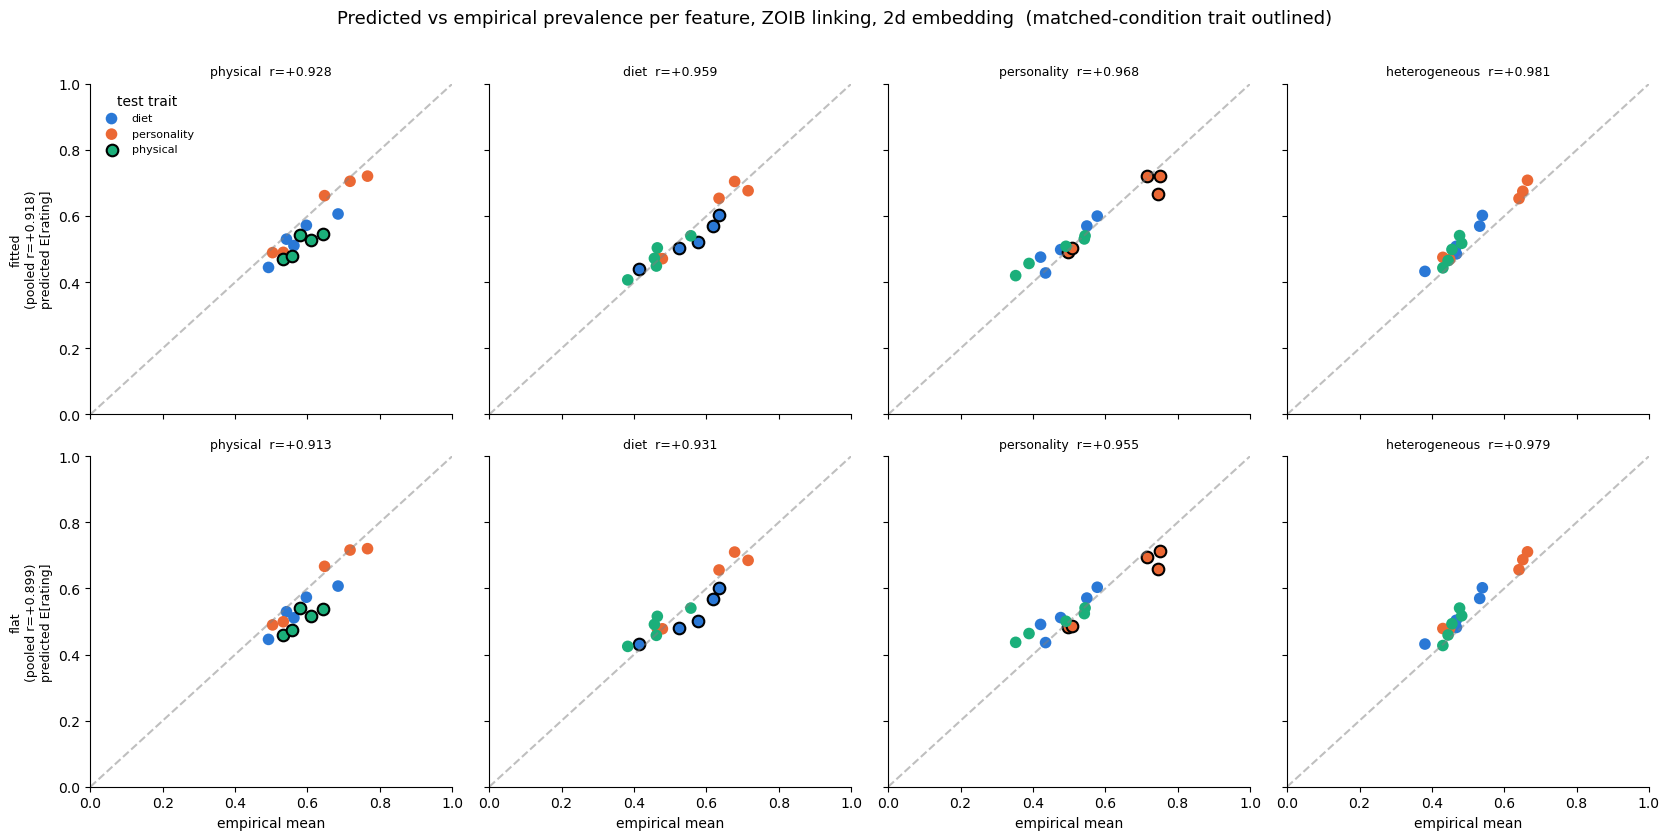

In [9]:
traits = np.array(test_trait)
fig, axgrid = plt.subplots(len(MODELS), len(inf.CONDITIONS),
                           figsize=(4.2*len(inf.CONDITIONS), 4.2*len(MODELS)),
                           sharex=True, sharey=True)
for row, (name, m) in enumerate(MODELS.items()):
    pred_cond = fitres[name]['pred_cond']
    for col, c in enumerate(inf.CONDITIONS):
        ax = axgrid[row, col]
        for tr in TRAIT_COLOR:
            mask = traits == tr
            ax.scatter(emp_cond[c][mask], pred_cond[c][mask], s=70, color=TRAIT_COLOR[tr],
                       edgecolor=('k' if tr == c else 'none'), linewidth=1.5,
                       label=tr if (row == 0 and col == 0) else None)
        ax.plot([0, 1], [0, 1], '--', color='gray', alpha=0.5)
        ax.set_xlim(0, 1); ax.set_ylim(0, 1)
        r = np.corrcoef(pred_cond[c], emp_cond[c])[0, 1]
        ax.set_title(f"{c}  r={r:+.3f}", fontsize=9)
        if col == 0:
            r_pool_row = np.corrcoef(np.concatenate([pred_cond[cc] for cc in inf.CONDITIONS]), emp_all)[0, 1]
            ax.set_ylabel(f"{name}\n(pooled r={r_pool_row:+.3f})\npredicted E[rating]", fontsize=9)
        if row == len(MODELS) - 1:
            ax.set_xlabel('empirical mean')
axgrid[0, 0].legend(fontsize=8, title='test trait', loc='upper left')
fig.suptitle('Predicted vs empirical prevalence per feature, ZOIB linking, 2d embedding  '
             '(matched-condition trait outlined)', fontsize=13, y=0.995)
plt.tight_layout(rect=[0, 0, 1, 0.985])
out_png = os.path.join(RESULTS, 'predicted-vs-empirical-scatter-comparison.png')
fig.savefig(out_png, dpi=150, bbox_inches='tight')
print('saved', out_png)
plt.show()

## 5. Common-scale comparison with the free-linking models

The `log Z` values above can't be compared with the free-linking runs (`results/study9-fit/`): the free
linking scores every rating as a **density** (exact 0/100 nudged to 0.005/0.995 first), while the ZOIB scores
exact 0/100 as **probabilities** (point masses). Here every model is scored on the **same discrete scale**:
the probability of each of the 101 slider values.

- slider value k gets the bin [(k − ½)/100, (k + ½)/100], with [0, 0.005] for 0 and [0.995, 1] for 100;
- **ZOIB**: P(k) = its point mass (at 0 / 100) + (1 − π0 − π1) × the Beta mass in that bin, per class, mixed by coherence;
- **free linking**: P(k) = its Beta-mixture mass in that bin;
- every model's P(k) sums to 1 over the 101 values, so log-likelihoods are directly comparable.

Coherence is each model's **ratings-free** prediction (training statements only) at its posterior-median θ,
plugged in (not integrated over), so this is a plug-in predictive log-likelihood.

Four models (fitted / flat length scale × ZOIB / free linking) plus two reference points that ignore the GP:
- **memorize: feature histogram**: each feature's own smoothed histogram over the 101 values, the same for
  every condition (the most a per-feature linking could ever get without coherence);
- **memorize: condition × feature histogram**: a separate histogram per condition and feature (saturated;
  it captures condition effects directly, by memorizing them).

Two versions: **in-sample** (linking and histograms fit to all participants) and **5-fold cross-validation
over participants** (stratified by condition): the linking / histograms are refit on 4/5 of participants and
scored on the held-out 1/5. θ stays at each model's full-data posterior median in every fold (refitting VBMC
per fold would take hours), so the held-out numbers slightly favor all four GP models equally.

In [9]:
from scipy.special import betainc

EDGES = np.concatenate([[0.0], (np.arange(100) + 0.5) / 100, [1.0]])     # 102 edges -> 101 bins
responses_nudged, _ = inf.load_responses(DATA_CSV)                       # the free linking fits on nudged ratings

def beta_bin_mass(a, b):
    # (J, 101) Beta probability of each slider value's bin, for per-feature shapes a, b (J,)
    F = betainc(np.asarray(a)[:, None], np.asarray(b)[:, None], EDGES[None, :])
    return np.diff(F, axis=1)

def probs_free(shapes, pz1_c):
    # (J, 101) slider-value probabilities under the free Beta-mixture linking at coherence pz1_c (J,)
    P_kl, P_nkl = beta_bin_mass(shapes[:, 0], shapes[:, 1]), beta_bin_mass(shapes[:, 2], shapes[:, 3])
    w = np.asarray(pz1_c)[:, None]
    return w * P_kl + (1 - w) * P_nkl

def probs_zoib(link_theta, pz1_c):
    # (J, 101) slider-value probabilities under the per-feature ZOIB at coherence pz1_c (J,)
    q = lk.params_to_numpy(lk.unpack(jnp.asarray(link_theta)))
    out = []
    for c in ('kl', 'nkl'):
        P = (1 - q['pi0_' + c] - q['pi1_' + c])[:, None] * beta_bin_mass(q['a_' + c], q['b_' + c])
        P[:, 0] += q['pi0_' + c]; P[:, 100] += q['pi1_' + c]
        out.append(P)
    w = np.asarray(pz1_c)[:, None]
    return w * out[0] + (1 - w) * out[1]

def score(P, R):
    # summed log-probability of ratings R (N, J) in [0, 1] under per-feature value probabilities P (J, 101)
    k = np.round(np.asarray(R) * 100).astype(int)
    return float(np.sum(np.log(np.maximum(P[np.arange(P.shape[0])[None, :], k], 1e-300))))

def hist_probs(R, alpha=0.5):
    # (J, 101) smoothed per-feature histogram of ratings R (N, J)
    k = np.round(np.asarray(R) * 100).astype(int)
    C = np.stack([np.bincount(k[:, j], minlength=101) for j in range(k.shape[1])]).astype(float) + alpha
    return C / C.sum(1, keepdims=True)

# the four GP models: theta (posterior median) + which linking
FREE_POST = {'fitted': 'results/study9-fit/fitted-feature-shapes.npz', 'flat': 'results/study9-fit/fitted-feature-shapes-null.npz'}
def med(path):
    z = np.load(path, allow_pickle=True)
    return tuple(float(np.median(z[k])) for k in ('ls_samples', 'mu0_samples', 'sigma_samples', 'beta_samples'))
GPM = {}
for n in ('fitted', 'flat'):
    GPM[f'ZOIB, {n}'] = {'link': 'zoib', 'theta': (MODELS[n]['ls'], MODELS[n]['mu_0'], MODELS[n]['sigma'], MODELS[n]['beta'])}
    GPM[f'free, {n}'] = {'link': 'free', 'theta': med(FREE_POST[n])}
for n, g in GPM.items():
    ls, mu0, sig, b = g['theta']
    g['pz1'] = {c: np.asarray(v) for c, v in inf.prior_pz1_modes(geom, ls, mu0, sig, beta_speaker=b).items()}
    print(f"{n:<14} ls={ls:<7.3g} mu_0={mu0:+.3f} sigma={sig:.3f} beta={b:.3f}")

def fit_and_probs(g, train_raw, train_nudged):
    # fit the model's linking on the training ratings; return {condition: (J, 101)} value probabilities
    if g['link'] == 'zoib':
        th, _ = lk.fit(train_raw, g['pz1'])
        return {c: probs_zoib(th, g['pz1'][c]) for c in inf.CONDITIONS}
    shapes = inf.fit_link_shapes(train_nudged, g['pz1'])
    return {c: probs_free(shapes, g['pz1'][c]) for c in inf.CONDITIONS}

# sanity: every model's value probabilities sum to 1
_chk = fit_and_probs(GPM['ZOIB, fitted'], responses_cond, responses_nudged)
assert all(np.allclose(v.sum(1), 1) for v in _chk.values())
_chk = fit_and_probs(GPM['free, fitted'], responses_cond, responses_nudged)
assert all(np.allclose(v.sum(1), 1) for v in _chk.values())
print('value probabilities sum to 1 for both linkings')

ZOIB, fitted   ls=0.344   mu_0=+1.293 sigma=0.522 beta=25.931
free, fitted   ls=0.978   mu_0=+0.006 sigma=0.526 beta=0.907
ZOIB, flat     ls=10      mu_0=+1.480 sigma=0.429 beta=22.801
free, flat     ls=10      mu_0=-0.076 sigma=0.479 beta=0.733


value probabilities sum to 1 for both linkings


### 5a. In-sample (all participants)

In [10]:
def evaluate(train_idx, test_idx):
    # summed discrete log-lik of the test participants for every model; linking/histograms fit on train
    tr_raw = {c: np.asarray(responses_cond[c])[train_idx[c]] for c in inf.CONDITIONS}
    tr_nud = {c: np.asarray(responses_nudged[c])[train_idx[c]] for c in inf.CONDITIONS}
    te_raw = {c: np.asarray(responses_cond[c])[test_idx[c]] for c in inf.CONDITIONS}
    out = {}
    for n, g in GPM.items():
        P = fit_and_probs(g, tr_raw, tr_nud)
        out[n] = {c: score(P[c], te_raw[c]) for c in inf.CONDITIONS}
    H_feat = hist_probs(np.concatenate([tr_raw[c] for c in inf.CONDITIONS]))
    out['memorize: feature histogram'] = {c: score(H_feat, te_raw[c]) for c in inf.CONDITIONS}
    out['memorize: condition × feature histogram'] = {c: score(hist_probs(tr_raw[c]), te_raw[c]) for c in inf.CONDITIONS}
    return out

ALL = {c: np.arange(N_cond[c]) for c in inf.CONDITIONS}
insample = evaluate(ALL, ALL)
ins = pd.DataFrame(insample).T[list(inf.CONDITIONS)]
ins['TOTAL'] = ins.sum(axis=1)
ins['per rating'] = ins['TOTAL'] / (sum(N_cond.values()) * J)
ins.round(2)

,physical,diet,personality,heterogeneous,TOTAL,per rating
"ZOIB, fitted",-6288.96,-6261.49,-6805.73,-6666.34,-26022.52,-4.33
"free, fitted",-6384.23,-6399.42,-6909.71,-6782.48,-26475.84,-4.40
"ZOIB, flat",-6288.43,-6264.75,-6809.88,-6665.21,-26028.26,-4.33
"free, flat",-6374.20,-6390.79,-6905.13,-6774.05,-26444.18,-4.40
memorize: feature histogram,-5459.73,-5408.52,-5900.36,-5678.07,-22446.69,-3.73
memorize: condition × feature histogram,-5221.74,-5195.13,-5679.14,-5442.81,-21538.82,-3.58


### 5b. 5-fold cross-validation over participants

In [11]:
K_FOLDS = 5
rng = np.random.default_rng(0)
perm = {c: rng.permutation(N_cond[c]) for c in inf.CONDITIONS}
fold_of = {c: np.empty(N_cond[c], int) for c in inf.CONDITIONS}
for c in inf.CONDITIONS:
    fold_of[c][perm[c]] = np.arange(N_cond[c]) % K_FOLDS

cv = {}
for k in range(K_FOLDS):
    tr = {c: np.where(fold_of[c] != k)[0] for c in inf.CONDITIONS}
    te = {c: np.where(fold_of[c] == k)[0] for c in inf.CONDITIONS}
    res = evaluate(tr, te)
    for n, v in res.items():
        for c, s in v.items():
            cv[(n, c)] = cv.get((n, c), 0.0) + s
    print(f"fold {k + 1}/{K_FOLDS} done")

cvt = pd.Series(cv).unstack()[list(inf.CONDITIONS)]
cvt['TOTAL'] = cvt.sum(axis=1)
cvt['per rating'] = cvt['TOTAL'] / (sum(N_cond.values()) * J)
cvt = cvt.loc[list(insample)]
cvt.round(2)

fold 1/5 done


fold 2/5 done


fold 3/5 done


fold 4/5 done


fold 5/5 done


,physical,diet,personality,heterogeneous,TOTAL,per rating
"ZOIB, fitted",-6309.65,-6277.93,-6823.19,-6693.89,-26104.65,-4.34
"free, fitted",-6402.49,-6413.07,-6922.29,-6806.83,-26544.67,-4.41
"ZOIB, flat",-6310.64,-6281.95,-6828.56,-6694.31,-26115.46,-4.34
"free, flat",-6394.33,-6404.19,-6915.16,-6796.68,-26510.35,-4.41
memorize: feature histogram,-5776.89,-5717.15,-6224.95,-6039.36,-23758.36,-3.95
memorize: condition × feature histogram,-5939.51,-5870.73,-6412.37,-6193.76,-24416.37,-4.06


,in-sample total,held-out total,held-out vs feature histogram,"held-out vs ZOIB, flat"
"ZOIB, fitted",-26022.5,-26104.7,-2346.3,10.8
"free, fitted",-26475.8,-26544.7,-2786.3,-429.2
"ZOIB, flat",-26028.3,-26115.5,-2357.1,0.0
"free, flat",-26444.2,-26510.4,-2752.0,-394.9
memorize: feature histogram,-22446.7,-23758.4,0.0,2357.1
memorize: condition × feature histogram,-21538.8,-24416.4,-658.0,1699.1


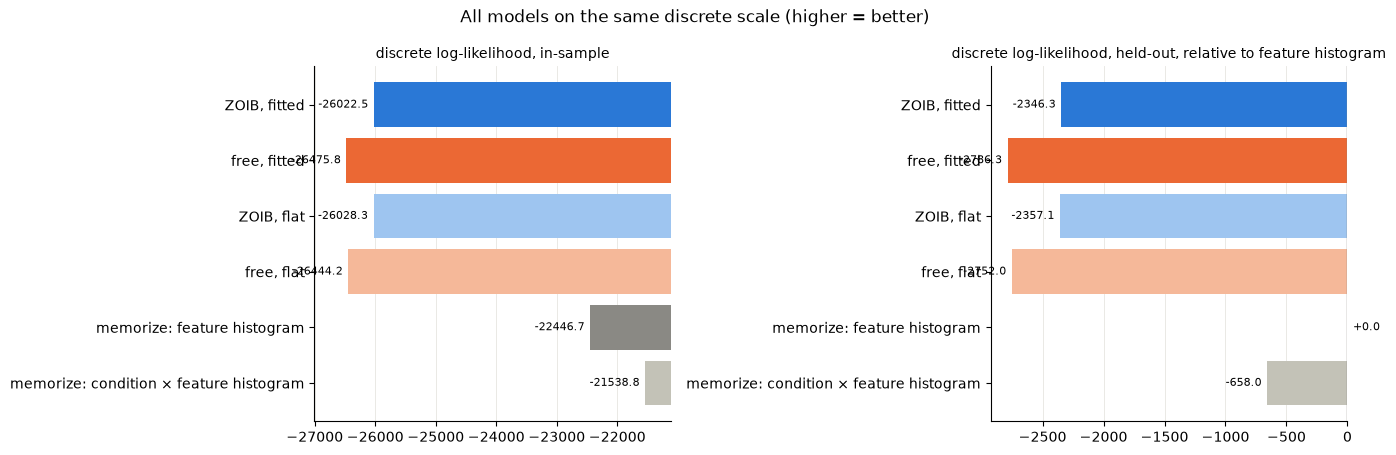

In [12]:
ref = 'memorize: feature histogram'
summ = pd.DataFrame({'in-sample total': ins['TOTAL'], 'held-out total': cvt['TOTAL']})
summ['held-out vs feature histogram'] = cvt['TOTAL'] - cvt.loc[ref, 'TOTAL']
summ['held-out vs ZOIB, flat'] = cvt['TOTAL'] - cvt.loc['ZOIB, flat', 'TOTAL']
display(summ.round(1))

order = list(cvt.index)
colors = {'ZOIB, fitted': '#2a78d6', 'ZOIB, flat': '#9ec5f0', 'free, fitted': '#eb6834', 'free, flat': '#f5b899',
          'memorize: feature histogram': '#8a8984', 'memorize: condition × feature histogram': '#c3c2b7'}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for ax, (col, lab) in zip(axes, [('in-sample total', 'in-sample'), ('held-out vs feature histogram', 'held-out, relative to feature histogram')]):
    vals = summ[col].loc[order]
    ax.barh(range(len(order)), vals, color=[colors[n] for n in order])
    for i, v in enumerate(vals):
        ax.annotate(f"{v:+.1f}" if 'relative' in lab else f"{v:.1f}", (v, i), xytext=(4 if v >= 0 else -4, 0),
                    textcoords='offset points', va='center', ha='left' if v >= 0 else 'right', fontsize=8)
    ax.set_yticks(range(len(order))); ax.set_yticklabels(order); ax.invert_yaxis()
    ax.axvline(0, color='#8a8984', lw=1)
    ax.set_title(f"discrete log-likelihood, {lab}", fontsize=10)
    ax.grid(axis='x', color='#e6e5e1', lw=0.6); ax.set_axisbelow(True)
axes[0].set_xlim(summ['in-sample total'].min() * 1.02, summ['in-sample total'].max() * 0.98)
fig.suptitle('All models on the same discrete scale (higher = better)', fontsize=12)
fig.tight_layout(); plt.show()

### 5c. Coarse scale: 10-point bins

On the fine (101-value) scale the histograms win by a wide margin, but mostly for a reason unrelated to the
GP: people over-use round numbers (25, 75, 10, 20, ...; ~17% of ratings land on multiples of 10 other than
0/50/100). A histogram memorizes those spikes; no smooth density can. To compare the models on what they are
built to capture, the same scoring is repeated on a **coarse scale**: 12 bins, `{0}`, `1–9`, `10–19`, …,
`90–99`, `{100}` (50 falls in `50–59`). Within-bin spikes no longer matter, while exact 0 and 100 keep their
own bins.

In [13]:
GROUPS = [np.array([0])] + [np.arange(max(1, lo), lo + 10) for lo in range(0, 100, 10)] + [np.array([100])]
GROUP_OF = np.empty(101, int)
for g, vals in enumerate(GROUPS):
    GROUP_OF[vals] = g
assert sorted(np.concatenate(GROUPS).tolist()) == list(range(101))

def coarse(P):
    # (J, 101) -> (J, 12) probabilities of the coarse bins
    return np.stack([P[:, vals].sum(1) for vals in GROUPS], axis=1)

def score_coarse(P, R):
    k = GROUP_OF[np.round(np.asarray(R) * 100).astype(int)]
    Pc = coarse(P)
    return float(np.sum(np.log(np.maximum(Pc[np.arange(Pc.shape[0])[None, :], k], 1e-300))))

def hist_probs_coarse(R, alpha=0.5):
    # smoothed histogram over the 12 coarse bins, spread evenly within each bin (so coarse() recovers it)
    k = GROUP_OF[np.round(np.asarray(R) * 100).astype(int)]
    C = np.stack([np.bincount(k[:, j], minlength=len(GROUPS)) for j in range(k.shape[1])]).astype(float) + alpha
    C /= C.sum(1, keepdims=True)
    P = np.zeros((C.shape[0], 101))
    for g, vals in enumerate(GROUPS):
        P[:, vals] = C[:, [g]] / len(vals)
    return P

def evaluate_coarse(train_idx, test_idx):
    tr_raw = {c: np.asarray(responses_cond[c])[train_idx[c]] for c in inf.CONDITIONS}
    tr_nud = {c: np.asarray(responses_nudged[c])[train_idx[c]] for c in inf.CONDITIONS}
    te_raw = {c: np.asarray(responses_cond[c])[test_idx[c]] for c in inf.CONDITIONS}
    out = {}
    for n, g in GPM.items():
        P = fit_and_probs(g, tr_raw, tr_nud)
        out[n] = {c: score_coarse(P[c], te_raw[c]) for c in inf.CONDITIONS}
    H_feat = hist_probs_coarse(np.concatenate([tr_raw[c] for c in inf.CONDITIONS]))
    out['memorize: feature histogram'] = {c: score_coarse(H_feat, te_raw[c]) for c in inf.CONDITIONS}
    out['memorize: condition × feature histogram'] = {c: score_coarse(hist_probs_coarse(tr_raw[c]), te_raw[c])
                                                      for c in inf.CONDITIONS}
    return out

ins_c = pd.DataFrame(evaluate_coarse(ALL, ALL)).T[list(inf.CONDITIONS)]
cv_c = {}
for k in range(K_FOLDS):
    tr = {c: np.where(fold_of[c] != k)[0] for c in inf.CONDITIONS}
    te = {c: np.where(fold_of[c] == k)[0] for c in inf.CONDITIONS}
    for n, v in evaluate_coarse(tr, te).items():
        for c, s in v.items():
            cv_c[(n, c)] = cv_c.get((n, c), 0.0) + s
cvt_c = pd.Series(cv_c).unstack()[list(inf.CONDITIONS)].loc[list(ins_c.index)]
summ_c = pd.DataFrame({'in-sample total': ins_c.sum(axis=1), 'held-out total': cvt_c.sum(axis=1)})
summ_c['held-out per rating'] = summ_c['held-out total'] / (sum(N_cond.values()) * J)
summ_c['held-out vs feature histogram'] = summ_c['held-out total'] - summ_c.loc['memorize: feature histogram', 'held-out total']
summ_c['held-out vs ZOIB, flat'] = summ_c['held-out total'] - summ_c.loc['ZOIB, flat', 'held-out total']
print(f"reference: uniform over the 12 bins would score {np.log(1 / 12):.3f} per rating")
display(cvt_c.assign(TOTAL=cvt_c.sum(axis=1)).round(1))
summ_c.round(2)

reference: uniform over the 12 bins would score -2.485 per rating


,physical,diet,personality,heterogeneous,TOTAL
"ZOIB, fitted",-3501.0,-3390.8,-3564.3,-3572.2,-14028.2
"free, fitted",-3572.7,-3486.4,-3615.1,-3667.9,-14342.2
"ZOIB, flat",-3500.1,-3393.6,-3569.2,-3571.7,-14034.6
"free, flat",-3564.8,-3477.4,-3608.4,-3658.0,-14308.7
memorize: feature histogram,-3465.4,-3363.7,-3522.3,-3534.9,-13886.3
memorize: condition × feature histogram,-3510.8,-3444.2,-3558.7,-3629.5,-14143.3


,in-sample total,held-out total,held-out per rating,held-out vs feature histogram,"held-out vs ZOIB, flat"
"ZOIB, fitted",-13957.66,-14028.25,-2.33,-141.96,6.32
"free, fitted",-14279.33,-14342.18,-2.38,-455.89,-307.61
"ZOIB, flat",-13961.35,-14034.57,-2.33,-148.28,0.00
"free, flat",-14248.10,-14308.65,-2.38,-422.37,-274.08
memorize: feature histogram,-13709.82,-13886.28,-2.31,0.00,148.28
memorize: condition × feature histogram,-13412.38,-14143.27,-2.35,-256.99,-108.70


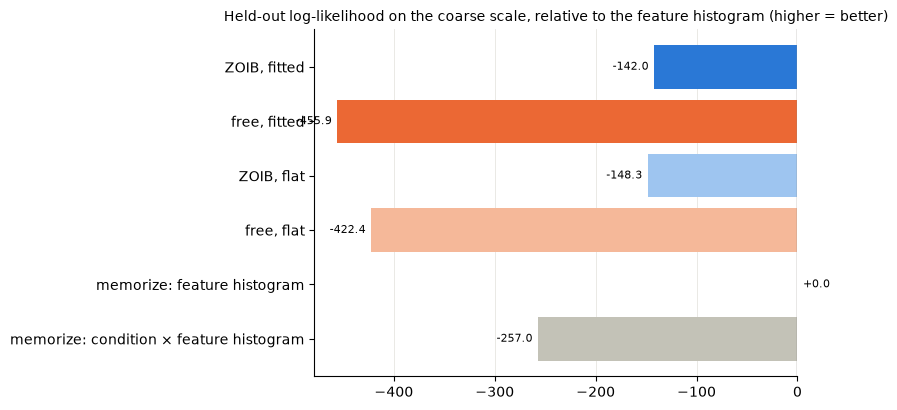

In [14]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
vals = summ_c['held-out vs feature histogram'].loc[order]
ax.barh(range(len(order)), vals, color=[colors[n] for n in order])
for i, v in enumerate(vals):
    ax.annotate(f"{v:+.1f}", (v, i), xytext=(4 if v >= 0 else -4, 0), textcoords='offset points',
                va='center', ha='left' if v >= 0 else 'right', fontsize=8)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order); ax.invert_yaxis()
ax.axvline(0, color='#8a8984', lw=1)
ax.set_title('Held-out log-likelihood on the coarse scale, relative to the feature histogram (higher = better)', fontsize=10)
ax.grid(axis='x', color='#e6e5e1', lw=0.6); ax.set_axisbelow(True)
fig.tight_layout(); plt.show()

**How to read this.**
- Every number is a log-probability of the observed slider values, so the four GP models and the two
  histograms are on one scale. Differences of a few units are small; tens are large.
- **fitted vs flat** within a linking (blue pair, orange pair): the value of distance-based generalization,
  measured the same way for both linkings.
- **ZOIB vs free**: whether the ZOIB's point masses and single-peaked components describe the ratings
  better once both are scored as probabilities.
- **vs the feature histogram**: whether a model beats simply memorizing each feature's distribution.
  Anything a GP model gains beyond it has to come from coherence differing across conditions.
- **condition × feature histogram**: the saturated reference; the gap between the two histograms is roughly
  how much there is to gain from condition information at all (it overfits, so its held-out number is the
  fairer one).

### 5d. What this shows (as of this run)

Held-out (5-fold) totals, higher = better:

| | fine scale (101 values) | coarse scale (12 bins) |
|---|---|---|
| ZOIB, fitted | −26104.7 | −14028.2 |
| ZOIB, flat | −26115.5 | −14034.6 |
| free, fitted | −26544.7 | −14342.2 |
| free, flat | −26510.4 | −14308.7 |
| memorize: feature histogram | −23758.4 | −13886.3 |
| memorize: condition × feature histogram | −24416.4 | −14143.3 |

- **ZOIB beats the free linking by ~300–440** on both scales, once both are scored as probabilities. The free
  linking's much higher `log Z` in `results/study9-fit/` came from scoring nudged 0/100 answers as densities,
  not from a better fit.
- **Fitted beats flat under the ZOIB** (+10.8 fine, +6.3 coarse, held out), consistent with the `log Z` / ELBO
  difference in section 1. **Under the free linking, flat beats fitted** (−34), so distance-based generalization
  only helps once the linking is constrained.
- **The feature histogram still beats every GP model** (by ~140 on the coarse scale, ~2350 on the fine scale,
  where it memorizes round-number spikes). So the per-feature ZOIB shapes don't yet describe each feature's
  distribution as well as a plain histogram does; the remaining gap is in the linking's shape, not in coherence.
- **The condition × feature histogram does worse than the feature histogram held out**: memorizing each
  condition separately overfits by more than the condition information is worth at this sample size (~100
  participants per condition). That caps how much any model can gain from condition effects here, and fits
  the small within-feature R² of the GP models.